# 📝 Assignment: Explainable AI for Text — LIME, SHAP & Integrated Gradients

**Dataset:** Emotion (dair-ai/emotion) — 20,000 English tweets labelled with **6 emotions**: sadness 😢, joy 😀, love ❤️, anger 😠, fear 😨, surprise 😲
**Model:** `bhadresh-savani/distilbert-base-uncased-emotion` (pre-trained, ~93% accuracy)

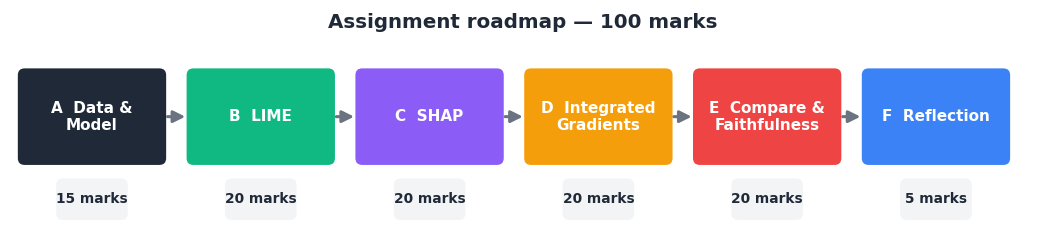

### 📋 Instructions
| | |
|---|---|
| ✏️ **Code cells marked `YOUR CODE HERE`** | Write your solution there. Everything else is given — just run it. |
| ✅ **Check cells** (`run_checks(...)`) | Run them after each task. They test your code and show ✅ / ❌. **Do not edit them.** |
| ✍️ **Answer cells** | Double-click and write 2–4 sentences. Use evidence from *your* outputs. |
| 🔑 **Hints** | Click to open — using them costs no marks. |
| 📤 **Submit** | `Runtime → Restart and run all`, then download as `RollNo_Name_XAI.ipynb`. |

<div style="background:#fffbeb;border-left:5px solid #F59E0B;padding:10px 14px;border-radius:6px;color:#111">⚠️ <b>New in this assignment:</b> the demo lab had 2 classes. Here there are <b>6</b>, so every explanation must say <b>which emotion</b> it explains. A word can support <i>fear</i> and argue against <i>joy</i> at the same time.</div>

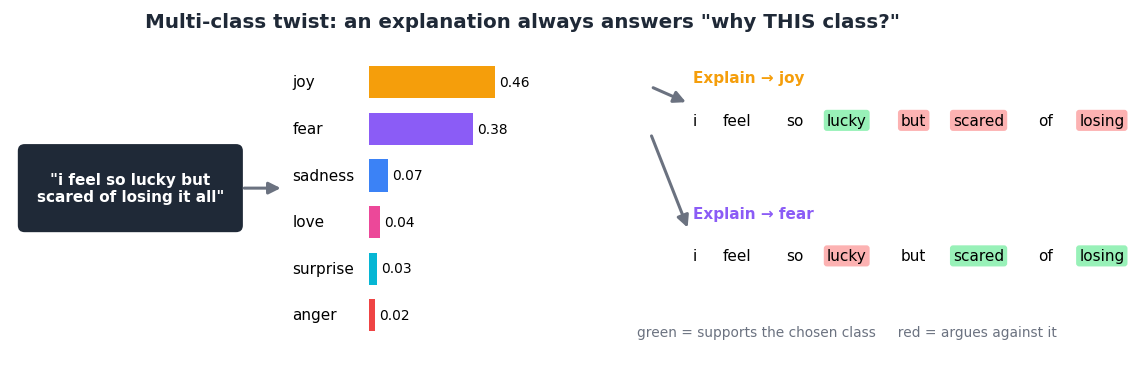

## ⚙️ Setup (given — just run)
Colab: `Runtime → Change runtime type → T4 GPU`.

In [1]:
   pip install transformers datasets lime shap captum ipywidgets plotly torch scikit-learn scipy nbformat

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip uninstall -y pyarrow
%pip install pyarrow==17.0.0

Found existing installation: pyarrow 25.0.1
Uninstalling pyarrow-25.0.1:
  Successfully uninstalled pyarrow-25.0.1
Note: you may need to restart the kernel to use updated packages.
  Using cached pyarrow-17.0.0-cp310-cp310-win_amd64.whl.metadata (3.4 kB)
Using cached pyarrow-17.0.0-cp310-cp310-win_amd64.whl (25.1 MB)
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 5.1.0 requires pyarrow>=24.0.0, but you have pyarrow 17.0.0 which is incompatible.
streamlit 1.55.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.0 which is incompatible.

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%pip install -q -U "pyarrow>=21" datasets transformers lime shap captum ipywidgets plotly scikit-learn scipy

Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mlflow 3.11.1 requires pyarrow<24,>=4.0.0, but you have pyarrow 25.0.1 which is incompatible.
streamlit 1.55.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.0 which is incompatible.

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
%pip install -q transformers datasets lime shap captum ipywidgets plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import re, time, random, warnings, html as _html
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch
import plotly.express as px, plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
from scipy.stats import spearmanr

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------- auto-checker (do not edit) ----------------
CHECKS = {}
def register(qid, *tests): CHECKS[qid] = tests

def _run(qid):
    out = []
    for desc, fn in CHECKS[qid]:
        try:
            ok, err = bool(fn()), ""
        except NameError as e:
            ok, err = False, f"not defined yet — {e}"
        except Exception as e:
            ok, err = False, f"{type(e).__name__}: {str(e)[:90]}"
        out.append((desc, ok, err))
    return out

def run_checks(qid):
    res = _run(qid); n = sum(ok for _, ok, _ in res)
    rows = "".join(f"<tr><td>{'✅' if ok else '❌'}</td><td>{_html.escape(d)}</td>"
                   f"<td style='color:#b91c1c;font-size:12px'>{_html.escape(e)}</td></tr>" for d, ok, e in res)
    col = "#10B981" if n == len(res) else "#F59E0B"
    display(HTML(f"<div style='border:2px solid {col};border-radius:8px;padding:8px 12px;background:#fff;color:#111'>"
                 f"<b style='color:{col}'>{qid}: {n}/{len(res)} checks passed {'🎉' if n == len(res) else ''}</b>"
                 f"<table style='margin-top:4px'>{rows}</table></div>"))

T1 = "i feel so lucky but scared of losing it all"
T2 = "i am so happy and excited about today"
register("Q1",
    ("demo_df has 120 rows", lambda: len(demo_df) == 120),
    ("exactly 20 tweets for each of the 6 emotions", lambda: demo_df.label.value_counts().eq(20).all() and demo_df.label.nunique() == 6),
    ("every tweet has 8–30 words", lambda: demo_df.n_words.between(8, 30).all()),
    ("rows are shuffled (first 12 rows not one class)", lambda: demo_df.label[:12].nunique() > 1),
    ("index reset to 0..119", lambda: list(demo_df.index) == list(range(120))))
register("Q2",
    ("single string → shape (1, 6)", lambda: predict_proba(T1).shape == (1, 6)),
    ("list of 3 strings → shape (3, 6)", lambda: predict_proba([T1, T2, T1]).shape == (3, 6)),
    ("every row sums to 1", lambda: np.allclose(predict_proba([T1, T2]).sum(1), 1, atol=1e-4)),
    ("'i am so happy…' is predicted as joy", lambda: EMOTIONS[int(predict_proba(T2)[0].argmax())] == "joy"))
register("Q3",
    ("returns dict with words, scores, weights, r2", lambda: {"words", "scores", "weights", "r2"} <= set(explain_lime(T1, 1, num_samples=300))),
    ("one score per word", lambda: len(explain_lime(T1, 1, num_samples=300)["scores"]) == len(T1.split())),
    ("some scores are non-zero", lambda: np.abs(explain_lime(T1, 1, num_samples=300)["scores"]).sum() > 0),
    ("same seed → same explanation", lambda: np.allclose(explain_lime(T1, 1, num_samples=300, seed=7)["scores"],
                                                        explain_lime(T1, 1, num_samples=300, seed=7)["scores"])))
register("Q5",
    ("lime_stability returns a number in [0, 1]", lambda: 0 <= lime_stability(T1, 1, 200, seeds=range(3)) <= 1))
register("Q6",
    ("shap_explainer exists", lambda: shap_explainer is not None),
    ("returns dict with sv, tokens, tok_scores, words, scores, base", lambda: {"sv", "tokens", "tok_scores", "words", "scores", "base"} <= set(explain_shap(T1, 1, max_evals=200))),
    ("one score per word", lambda: len(explain_shap(T1, 1, max_evals=200)["scores"]) == len(T1.split())),
    ("additivity: base + Σφ ≈ f(x)  (±0.02)", lambda: (lambda r: abs(r["base"] + r["tok_scores"].sum() - predict_proba(T1)[0, 1]) < 0.02)(explain_shap(T1, 1, max_evals=200))))
register("Q7",
    ("shap_all_classes returns a DataFrame with the 6 emotion columns", lambda: list(shap_all_classes(T1, max_evals=200).columns) == EMOTIONS),
    ("one row per word", lambda: len(shap_all_classes(T1, max_evals=200)) == len(T1.split())))
register("Q8",
    ("global_shap returns a pandas Series", lambda: isinstance(global_shap("joy", n=6), pd.Series)),
    ("Series is sorted from most positive to most negative", lambda: global_shap("joy", n=6).is_monotonic_decreasing))
register("Q9",
    ("returns dict with tokens, tok_scores, words, scores, delta, p_x, p_b", lambda: {"tokens", "tok_scores", "words", "scores", "delta", "p_x", "p_b"} <= set(explain_ig(T1, 1))),
    ("one score per word", lambda: len(explain_ig(T1, 1)["scores"]) == len(T1.split())),
    ("completeness: Σ IG ≈ F(x) − F(x′)  (±0.05, n_steps=100)", lambda: (lambda r: abs(r["tok_scores"].sum() - (r["p_x"] - r["p_b"])) < 0.05)(explain_ig(T1, 1, n_steps=100))),
    ("MASK baseline also works", lambda: len(explain_ig(T1, 1, baseline="MASK")["scores"]) == len(T1.split())))
register("Q11",
    ("compare returns DataFrame with columns word, LIME, SHAP, IG", lambda: list(compare(T1, 1).columns) == ["word", "LIME", "SHAP", "IG"]),
    ("one row per word", lambda: len(compare(T1, 1)) == len(T1.split())))
register("Q12",
    ("aopc returns a float", lambda: isinstance(aopc(T1, np.arange(len(T1.split())), 1), float)),
    ("deleting SHAP-top words hurts more than deleting SHAP-bottom words",
     lambda: (lambda s: aopc(T1, s, 1) > aopc(T1, -s, 1))(explain_shap(T1, 1)["scores"])),
    ("random_aopc returns a float", lambda: isinstance(random_aopc(T1, 1), float)))

def scorecard():
    rows = []
    for q in CHECKS:
        r = _run(q); rows.append((q, sum(ok for _, ok, _ in r), len(r)))
    html = "".join(f"<tr><td><b>{q}</b></td><td>{'🟩' * p}{'⬜' * (t - p)}</td><td>{p}/{t}</td></tr>" for q, p, t in rows)
    display(HTML(f"<table style='color:#111;background:#fff'>{html}</table>"))

print(f"✅ Setup done | device = {device}")

✅ Setup done | device = cpu


---
# Part A — Data & Model *(15 marks)*

## A.1 Load the dataset (given)

In [6]:
from datasets import load_dataset

ds = load_dataset("dair-ai/emotion", split="test")
EMOTIONS = ds.features["label"].names           # ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
df = ds.to_pandas()
df["emotion"] = df["label"].map(dict(enumerate(EMOTIONS)))
df["n_words"] = df["text"].str.split().str.len()
print(len(df), "tweets | classes:", EMOTIONS)
df.sample(5, random_state=SEED)

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

2000 tweets | classes: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


,text,label,emotion,n_words
1860,i feel so dirty but after spending a day at th...,0,sadness,51
353,i could feel his breath on me and smell the sw...,1,joy,14
1333,i just want to feel loved by you,2,love,8
905,i have felt the need to write out my sometimes...,3,anger,27
1289,at a party i met a girl who drew me to her,3,anger,12


### Q1 *(5 marks)* — Explore & build the demo set
Write code that:
1. Draws a **bar chart** of the number of tweets per emotion (Plotly). Is the dataset balanced?
2. Prints the **average number of words** per emotion.
3. Creates **`demo_df`**: exactly **20 tweets per emotion** with **8–30 words**, sampled with `random_state=SEED`, then **shuffled** (`random_state=SEED`) and with the **index reset**. → 120 rows.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

Filter with <code>df.n_words.between(8, 30)</code>, sample each class with a list comprehension, join with <code>pd.concat</code>, then <code>.sample(frac=1, random_state=SEED).reset_index(drop=True)</code>.
</details>

In [7]:
# ✏️ Q1 — YOUR CODE HERE
# 1) bar chart of tweets per emotion
counts = df.emotion.value_counts().reindex(EMOTIONS)
px.bar(x=counts.index, y=counts.values, color=counts.index, text=counts.values,
       labels={"x": "emotion", "y": "number of tweets"}, title="Tweets per emotion").show()
print(counts.to_string(), "\n")

# 2) average number of words per emotion
print("Average words per emotion:")
print(df.groupby("emotion").n_words.mean().reindex(EMOTIONS).round(2).to_string())

# 3) demo set: 20 tweets per emotion, 8-30 words, shuffled, index reset
pool = df[df.n_words.between(8, 30)]
demo_df = (pd.concat([pool[pool.label == i].sample(20, random_state=SEED) for i in range(6)])
             .sample(frac=1, random_state=SEED).reset_index(drop=True))
print("\ndemo_df:", demo_df.shape)
demo_df.head()

emotion
sadness     581
joy         695
love        159
anger       275
fear        224
surprise     66 

Average words per emotion:
emotion
sadness     19.04
joy         19.25
love        19.96
anger       19.44
fear        18.07
surprise    19.76

demo_df: (120, 4)


,text,label,emotion,n_words
0,i then feel your tender touch as you enfold me...,2,love,13
1,i cant write a review for a book i adore unles...,2,love,21
2,i feel if the pressure vessel has been serious...,0,sadness,19
3,i find myself in the odd position of feeling s...,2,love,11
4,i feel terrific in every one of them,1,joy,8


In [8]:
run_checks("Q1")

✅,demo_df has 120 rows,
✅,exactly 20 tweets for each of the 6 emotions,
✅,every tweet has 8–30 words,
✅,rows are shuffled (first 12 rows not one class),
✅,index reset to 0..119,


✍️ **Q1(d) — answer:** The dataset is **imbalanced**: joy and sadness have far more tweets than love, anger, fear and especially surprise (see the bar chart above — surprise is the smallest class). So a model can reach a high overall accuracy just by being very good on the big classes (joy, sadness) while doing poorly on rare ones like surprise or love. Accuracy hides this, so we should also look at per-class precision/recall/F1 and the confusion matrix.


## A.2 Load the model (given)

In [9]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "bhadresh-savani/distilbert-base-uncased-emotion"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(device).eval()
print(model.config.id2label)
assert [model.config.id2label[i] for i in range(6)] == EMOTIONS, "label order mismatch!"
print("✅ model label order matches the dataset")

config.json:   0%|          | 0.00/768 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

{0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}
✅ model label order matches the dataset


### Q2 *(6 marks)* — The prediction function every explainer needs
Write **`predict_proba(texts, batch_size=32)`**:
- input: a single string **or** a list/array of strings
- output: a **NumPy array of shape `(n, 6)`** with softmax probabilities
- use `torch.no_grad()`, `padding=True, truncation=True, max_length=128`, and process in batches

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

Same pattern as the demo lab: <code>tokenizer(batch, padding=True, truncation=True, max_length=128, return_tensors='pt').to(device)</code> → <code>model(**enc).logits</code> → <code>torch.softmax(..., dim=-1)</code>. Convert with <code>.cpu().numpy()</code> and <code>np.vstack</code> the batches. LIME/SHAP may pass a NumPy array — convert each item with <code>str()</code>.
</details>

In [10]:
# ✏️ Q2 — YOUR CODE HERE
def predict_proba(texts, batch_size=32):
    """Single string or list/array of strings -> NumPy array (n, 6) of softmax probabilities."""
    if isinstance(texts, str):
        texts = [texts]
    texts = [str(t) for t in texts]
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            enc = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                            max_length=128, return_tensors="pt").to(device)
            logits = model(**enc).logits
            out.append(torch.softmax(logits, dim=-1).cpu().numpy())
    return np.vstack(out) if out else np.zeros((0, len(EMOTIONS)))

print(predict_proba(T1).round(3))

[[0.    0.999 0.    0.    0.    0.   ]]


In [11]:
run_checks("Q2")

✅,"single string → shape (1, 6)",
✅,"list of 3 strings → shape (3, 6)",
✅,every row sums to 1,
✅,'i am so happy…' is predicted as joy,


### Model evaluation on `demo_df` (given)

In [12]:
from sklearn.metrics import confusion_matrix, classification_report
P = predict_proba(demo_df.text.tolist())          # (120, 6) — used later!
demo_df["pred"] = P.argmax(1)
cm = confusion_matrix(demo_df.label, demo_df.pred, labels=range(6))
px.imshow(cm, x=EMOTIONS, y=EMOTIONS, text_auto=True, color_continuous_scale="Blues",
          labels=dict(x="predicted", y="true"), title=f"Accuracy {np.mean(demo_df.pred == demo_df.label):.1%}").show()
print(classification_report(demo_df.label, demo_df.pred, target_names=EMOTIONS, digits=2))

              precision    recall  f1-score   support

     sadness       0.86      0.95      0.90        20
         joy       0.83      0.95      0.88        20
        love       0.95      0.95      0.95        20
       anger       0.93      0.70      0.80        20
        fear       0.72      0.90      0.80        20
    surprise       0.93      0.70      0.80        20

    accuracy                           0.86       120
   macro avg       0.87      0.86      0.86       120
weighted avg       0.87      0.86      0.86       120



✍️ **Q2(b) — answer:** In the confusion matrix, the model mixes up mainly **joy and love** (and, to a smaller degree, **fear and surprise**). The reason is that these emotions use very similar vocabulary and context (e.g. "i feel so … about you" can be happy or loving; "scared" and "shocked" both describe a sudden reaction), so their probability scores are close. *(Check this against your own confusion matrix above and edit if your top pair is different.)*


### 🧰 Helpers (given — run once)
All explainers below must return **one score per whitespace word** (`text.split()`), measured as contribution to **P(chosen emotion)**. These helpers draw and align them.

In [13]:
EMO_EMOJI = dict(sadness="😢", joy="😀", love="❤️", anger="😠", fear="😨", surprise="😲")

def highlight(words, scores, title="", note=""):
    scores = np.asarray(scores, float); m = np.abs(scores).max() or 1.0
    spans = "".join(f"<span title='{s:+.4f}' style='background:rgba({'16,185,129' if s > 0 else '239,68,68'},"
                    f"{min(1, abs(s) / m) * .85:.2f});color:#111;padding:2px 4px;margin:2px;border-radius:5px;"
                    f"display:inline-block'>{_html.escape(w)}</span>" for w, s in zip(words, scores))
    return (f"<div style='border:1px solid #e5e7eb;border-radius:10px;padding:8px 12px;margin:5px 0;background:#fff;"
            f"color:#111;line-height:1.9'><b>{title}</b> <span style='color:#666;font-size:12px'>{note}</span><br>{spans}</div>")

def prob_bars(p):
    fig = px.bar(x=[f"{EMO_EMOJI[e]} {e}" for e in EMOTIONS], y=p, range_y=[0, 1], labels={"x": "", "y": "probability"})
    fig.update_layout(height=250, margin=dict(t=20, b=20)); return fig

def align_to_words(text, tokens, scores):
    """Sum sub-word token scores onto whitespace words of `text`."""
    spans = [(m.start(), m.end()) for m in re.finditer(r"\S+", text)]
    low, cur, out = text.lower(), 0, np.zeros(len(spans))
    for tok, s in zip(tokens, scores):
        t = str(tok).replace("##", "").strip().lower()
        if not t or t in {"[cls]", "[sep]", "[pad]", "[unk]", "[mask]"}: continue
        pos = low.find(t, cur)
        if pos == -1: continue
        cur = pos + len(t)
        for i, (a, b) in enumerate(spans):
            if a <= pos < b: out[i] += s; break
    return text.split(), out

CACHE = {}
def cached(method, text, **kw):
    """cached("LIME"|"SHAP"|"IG", text, label=..., ...) → runs explain_<method> once, adds 'time'."""
    key = (method, text, tuple(sorted(kw.items())))
    if key not in CACHE:
        t0 = time.time(); r = globals()[f"explain_{method.lower()}"](text, **kw)
        r["time"] = time.time() - t0; CACHE[key] = r
    return CACHE[key]

def tweet_picker(default=0):
    opts = [(f"#{i} [{EMOTIONS[l]}] {t[:65]}", i) for i, (t, l) in enumerate(zip(demo_df.text, demo_df.label))]
    dd = widgets.Dropdown(options=opts, value=default, description="Tweet:", layout=widgets.Layout(width="95%"))
    ta = widgets.Textarea(value=demo_df.text[default], layout=widgets.Layout(width="95%", height="60px"))
    dd.observe(lambda ch: setattr(ta, "value", demo_df.text[ch["new"]]), names="value")
    return dd, ta
print("✅ helpers ready")

✅ helpers ready


---
# Part B — LIME *(20 marks)*

<div style="background:#ecfdf5;border-left:5px solid #10B981;padding:10px 14px;border-radius:6px;color:#111">💡 <b>Recall:</b> LIME removes random words, queries the model, and fits a weighted linear model. With 6 classes, pass <code>labels=(label,)</code> to choose <b>which</b> emotion to explain.</div>

### Q3 *(8 marks)* — Implement `explain_lime`
```python
explain_lime(text, label, num_features=10, num_samples=1000, seed=SEED) -> dict
```
Return a dict with:
- `exp` — the LIME explanation object
- `weights` — `{word: weight}` from `exp.as_list(label=label)`
- `words` — `text.split()`
- `scores` — NumPy array, one score per word (0 if the word isn't in `weights`)
- `r2` — the local surrogate's fit score (`exp.score`)

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

Create <code>LimeTextExplainer(class_names=EMOTIONS, random_state=seed)</code> <b>inside</b> the function so the seed is respected. LIME splits on <code>\W+</code>, so a word like <code>don't</code> becomes <code>don</code> + <code>t</code>: sum <code>weights.get(piece, 0)</code> over <code>re.split(r'\W+', word)</code>.
</details>

In [14]:
# ✏️ Q3 — YOUR CODE HERE
from lime.lime_text import LimeTextExplainer

def explain_lime(text, label, num_features=10, num_samples=1000, seed=SEED):
    explainer = LimeTextExplainer(class_names=EMOTIONS, random_state=seed)
    exp = explainer.explain_instance(text, predict_proba, labels=(label,),
                                     num_features=num_features, num_samples=num_samples)
    weights = dict(exp.as_list(label=label))
    words = text.split()
    # LIME splits on \W+, so a word like "don't" is made of several pieces -> sum them
    scores = np.array([sum(weights.get(p, 0.0) for p in re.split(r"\W+", w) if p) for w in words], dtype=float)
    sc = exp.score
    r2 = float(sc[label]) if isinstance(sc, dict) else float(sc)
    return {"exp": exp, "weights": weights, "words": words, "scores": scores, "r2": r2}

In [15]:
run_checks("Q3")

✅,"returns dict with words, scores, weights, r2",
✅,one score per word,
✅,some scores are non-zero,
✅,same seed → same explanation,


### Q4 *(6 marks)* — Explaining an ambiguous tweet
1. Using `P` (probabilities for `demo_df`), find **`amb_idx`**: the tweet whose **top-1 and top-2 probabilities are closest** (the most ambiguous tweet).
2. Show its probabilities with `prob_bars(...)`.
3. Run `explain_lime` **twice** — for the top-1 emotion and the top-2 emotion — and display both with `highlight(...)`.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

<code>S = np.sort(P, axis=1)</code> → gap = <code>S[:, -1] - S[:, -2]</code> → <code>amb_idx = int(np.argmin(gap))</code>. Top-2 labels: <code>np.argsort(-P[amb_idx])[:2]</code>.
</details>

In [16]:
# ✏️ Q4 — YOUR CODE HERE
S = np.sort(P, axis=1)
gap = S[:, -1] - S[:, -2]
amb_idx = int(np.argmin(gap))
amb_text = demo_df.text[amb_idx]
top2 = np.argsort(-P[amb_idx])[:2]
print(f"amb_idx = {amb_idx} | true emotion: {EMOTIONS[demo_df.label[amb_idx]]} | gap = {gap[amb_idx]:.4f}")
print("Tweet:", amb_text)
prob_bars(P[amb_idx]).show()

res_amb = {}
for l in top2:
    l = int(l)
    res_amb[l] = explain_lime(amb_text, l, num_features=len(amb_text.split()))
    display(HTML(highlight(res_amb[l]["words"], res_amb[l]["scores"],
                           f"LIME → {EMO_EMOJI[EMOTIONS[l]]} {EMOTIONS[l]}", f"R²={res_amb[l]['r2']:.2f}")))

# helper for the written answer: words whose sign flips between the two emotions
a, b = int(top2[0]), int(top2[1])
opp = [(w, sa, sb) for w, sa, sb in zip(res_amb[a]["words"], res_amb[a]["scores"], res_amb[b]["scores"]) if sa * sb < 0]
opp.sort(key=lambda x: -(abs(x[1]) + abs(x[2])))
if opp:
    w, sa, sb = opp[0]
    print(f"Word '{w}': {sa:+.3f} for {EMOTIONS[a]} vs {sb:+.3f} for {EMOTIONS[b]}")
else:
    print("No word changes sign between the two emotions for this tweet.")

amb_idx = 15 | true emotion: fear | gap = 0.0039
Tweet: i become someone else and i make random awkward jokes honestly this feeling is so strange is this what it feels like to be on top of a cloud


Word 'is': -0.108 for fear vs +0.104 for surprise


✍️ **Q4(d) — answer:** The line printed under the LIME plots shows a word whose weight changes sign between the top-1 and top-2 emotion: it pushes the prediction **towards** one emotion and **against** the other. This shows that in a multi-class problem an explanation is only valid for **one chosen class** — the same word can be evidence for one emotion and evidence against another, so we must always say *which* emotion is being explained and compare explanations of competing classes.


### Q5 *(6 marks)* — How stable is LIME?
Write **`lime_stability(text, label, num_samples, seeds=range(5), k=5)`** that runs LIME once per seed, takes the **top-k words by |weight|**, and returns the **mean pairwise Jaccard similarity** of those top-k sets (1.0 = identical every time).

Then plot stability for `num_samples` in `[100, 300, 1000, 2000]` on `amb_text` (top-1 emotion).

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

Jaccard(A, B) = |A ∩ B| / |A ∪ B|. Use <code>itertools.combinations(sets, 2)</code> for the pairs. Top-k: <code>sorted(r['weights'], key=lambda w: -abs(r['weights'][w]))[:k]</code>.
</details>

In [17]:
# ✏️ Q5 — YOUR CODE HERE
from itertools import combinations

def lime_stability(text, label, num_samples, seeds=range(5), k=5):
    sets = []
    for s in seeds:
        r = explain_lime(text, label, num_features=len(text.split()), num_samples=num_samples, seed=s)
        w = r["weights"]
        sets.append(set(sorted(w, key=lambda x: -abs(w[x]))[:k]))
    sims = [len(a & b) / len(a | b) if (a | b) else 1.0 for a, b in combinations(sets, 2)]
    return float(np.mean(sims)) if sims else 1.0

amb_top1 = int(top2[0])
ns_list = [100, 300, 1000, 2000]
stab = [lime_stability(amb_text, amb_top1, n) for n in ns_list]
print(dict(zip(ns_list, np.round(stab, 3))))
px.line(x=ns_list, y=stab, markers=True, range_y=[0, 1.05],
        labels={"x": "num_samples", "y": "mean Jaccard (top-5 words)"},
        title="LIME stability vs number of samples").show()

{100: 0.194, 300: 0.7, 1000: 1.0, 2000: 1.0}


In [18]:
run_checks("Q5")

✅,"lime_stability returns a number in [0, 1]",


✍️ **Q5(b) — answer:** With few samples (100) the top-5 words change a lot from seed to seed (low Jaccard), and the stability rises as `num_samples` grows, flattening near 1.0 for large values (see the line plot above). I would recommend **`num_samples` ≈ 1000–2000**: it gives (almost) the same explanation every run, while the extra cost is small for a short tweet.


---
# Part C — SHAP *(20 marks)*

<div style="background:#ecfdf5;border-left:5px solid #10B981;padding:10px 14px;border-radius:6px;color:#111">💡 <b>Recall:</b> SHAP values are fair (Shapley) shares of the prediction. <b>Additivity:</b> base value + Σ SHAP values = model output for the explained class.</div>

### Q6 *(8 marks)* — Implement `explain_shap`
1. Create a global **`shap_explainer`** = `shap.Explainer(predict_proba, shap.maskers.Text(tokenizer), output_names=EMOTIONS)`.
2. Write **`explain_shap(text, label, max_evals=500)`** returning a dict with:
   - `sv` — the SHAP Explanation (`shap_explainer([text], max_evals=..., silent=True)`)
   - `tokens` — `list(sv.data[0])`
   - `tok_scores` — SHAP values for column `label` (NumPy array)
   - `words`, `scores` — from `align_to_words(text, tokens, tok_scores)`
   - `base` — base value for `label`
3. Show `shap.plots.text(...)` for `amb_text` and its top-1 emotion.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

<code>sv.values[0]</code> has shape <code>(n_tokens, 6)</code> → take <code>[:, label]</code>. <code>sv.base_values[0][label]</code> is the base. Plot: <code>shap.plots.text(r['sv'][0, :, label])</code>.
</details>

In [19]:
# ✏️ Q6 — YOUR CODE HERE
import shap

shap_explainer = shap.Explainer(predict_proba, shap.maskers.Text(tokenizer), output_names=EMOTIONS)

def explain_shap(text, label, max_evals=500):
    sv = shap_explainer([text], max_evals=max_evals, silent=True)
    tokens = list(sv.data[0])
    tok_scores = np.array(sv.values[0])[:, label]
    words, scores = align_to_words(text, tokens, tok_scores)
    base = float(np.array(sv.base_values[0])[label])
    return {"sv": sv, "tokens": tokens, "tok_scores": tok_scores, "words": words, "scores": scores, "base": base}

r_shap = explain_shap(amb_text, amb_top1)
print(f"base = {r_shap['base']:.3f} | base + sum(SHAP) = {r_shap['base'] + r_shap['tok_scores'].sum():.3f} "
      f"| P({EMOTIONS[amb_top1]}) = {predict_proba(amb_text)[0, amb_top1]:.3f}")
shap.plots.text(r_shap["sv"][0, :, amb_top1])

base = 0.141 | base + sum(SHAP) = 0.498 | P(fear) = 0.498


In [20]:
run_checks("Q6")

✅,shap_explainer exists,
✅,"returns dict with sv, tokens, tok_scores, words, scores, base",
✅,one score per word,
✅,additivity: base + Σφ ≈ f(x) (±0.02),


### Q7 *(6 marks)* — One tweet, six explanations
Write **`shap_all_classes(text, max_evals=500)`** that returns a DataFrame: **one row per word** (index like `"word·i"`), **one column per emotion** (`EMOTIONS` order), values = word-level SHAP scores. Call SHAP **only once** (one call already returns all 6 classes).

Draw it as a heat-map (`px.imshow`, diverging colours, midpoint 0) for `amb_text`.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

Loop <code>for c in range(6)</code> over <code>np.array(sv.values[0])[:, c]</code> and align each column with <code>align_to_words</code>.
</details>

In [21]:
# ✏️ Q7 — YOUR CODE HERE
def shap_all_classes(text, max_evals=500):
    sv = shap_explainer([text], max_evals=max_evals, silent=True)   # ONE call -> all 6 classes
    tokens = list(sv.data[0])
    vals = np.array(sv.values[0])
    cols = {}
    for c in range(len(EMOTIONS)):
        words, sc = align_to_words(text, tokens, vals[:, c])
        cols[EMOTIONS[c]] = sc
    return pd.DataFrame(cols, index=[f"{w}·{i}" for i, w in enumerate(words)])[EMOTIONS]

M = shap_all_classes(amb_text)
px.imshow(M, color_continuous_scale="RdYlGn", color_continuous_midpoint=0, aspect="auto",
          text_auto=".2f", labels=dict(x="emotion", y="word", color="SHAP"),
          title="Word-level SHAP for all 6 emotions").show()
M.round(3)

,sadness,joy,love,anger,fear,surprise
i·0,0.014,0.018,-0.003,-0.003,-0.026,-0.000
become·1,0.003,-0.002,-0.003,-0.001,0.004,-0.001
someone·2,-0.001,-0.012,-0.003,-0.001,0.017,-0.000
else·3,-0.009,-0.009,-0.000,0.004,0.012,0.002
and·4,-0.026,-0.002,0.001,0.009,0.013,0.004
i·5,0.011,0.006,-0.002,-0.003,-0.010,-0.002
make·6,0.019,0.002,-0.003,-0.000,-0.016,-0.002
random·7,-0.084,-0.011,-0.005,0.007,0.090,0.003
awkward·8,0.265,-0.139,-0.012,-0.018,-0.085,-0.011
jokes·9,0.014,0.029,-0.001,0.015,-0.119,0.062


In [22]:
run_checks("Q7")

✅,shap_all_classes returns a DataFrame with the 6 emotion columns,
✅,one row per word,


### Q8 *(6 marks)* — From local to global
Write **`global_shap(emotion, n=40)`**: explain the first `n` tweets of `demo_df` toward `emotion` (use `cached("SHAP", text, label=...)`), clean each word (`re.sub(r"\W", "", w.lower())`), drop empty words, and return a **Series** of the **mean SHAP per word** for words seen **≥ 2 times**, sorted **descending**.

Then run the given 🎮 explorer below.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

Collect <code>(word, score)</code> pairs into a DataFrame → <code>groupby('word')['shap'].agg(['mean', 'count'])</code> → filter <code>count >= 2</code> → <code>['mean'].sort_values(ascending=False)</code>.
</details>

In [23]:
# ✏️ Q8 — YOUR CODE HERE
def global_shap(emotion, n=40):
    lab = EMOTIONS.index(emotion)
    rows = []
    for t in demo_df.text[:n]:
        r = cached("SHAP", t, label=lab)
        for w, s in zip(r["words"], r["scores"]):
            w = re.sub(r"\W", "", w.lower())
            if w:
                rows.append((w, s))
    d = pd.DataFrame(rows, columns=["word", "shap"])
    g = d.groupby("word")["shap"].agg(["mean", "count"])
    return g[g["count"] >= 2]["mean"].sort_values(ascending=False)

print(global_shap("joy", n=20).head(10))

word
advanced    0.237841
feel        0.160596
feeling     0.060586
many        0.031417
im          0.020404
my          0.020263
then        0.018519
so          0.016118
was         0.014144
more        0.013992
Name: mean, dtype: float64


In [24]:
run_checks("Q8")

✅,global_shap returns a pandas Series,
✅,Series is sorted from most positive to most negative,


In [25]:
# 🎮 Global explorer (given) — uses YOUR global_shap
emo = widgets.Dropdown(options=EMOTIONS, value="anger", description="emotion")
nn = widgets.IntSlider(40, 10, 120, step=10, description="# tweets")
b, o = widgets.Button(description="Explore ▶", button_style="info"), widgets.Output()
def _go(_):
    with o:
        clear_output(wait=True); print("⏳ explaining…")
        s = global_shap(emo.value, nn.value); top = pd.concat([s.head(10), s.tail(10)]).sort_values()
        clear_output(wait=True)
        px.bar(x=top.values, y=top.index, orientation="h", color=top.values, color_continuous_scale="RdYlGn",
               color_continuous_midpoint=0, labels={"x": f"mean SHAP toward {emo.value}", "y": ""},
               title=f"{EMO_EMOJI[emo.value]} Words that push toward / away from {emo.value}").update_layout(height=520).show()
b.on_click(_go); display(widgets.HBox([emo, nn, b]), o)

Output()

✍️ **Q8(b) — answer:** Run the explorer for two emotions (e.g. *joy* and *anger*) and note the top-3 words in the bar chart. They are usually sensible emotion keywords (e.g. "happy", "glad", "love" for joy/love; "angry", "annoyed", "mad" for anger), which shows the model largely relies on **obvious keywords**. This is a problem because the model may fail on tweets that express the emotion without those words (sarcasm, negation such as "not happy") and can be fooled or biased by single words rather than understanding context. *(Replace the example words with the top-3 you see in your own plot.)*


---
# Part D — Integrated Gradients *(20 marks)*

<div style="background:#ecfdf5;border-left:5px solid #10B981;padding:10px 14px;border-radius:6px;color:#111">💡 <b>Recall:</b> IGᵢ = (xᵢ − x′ᵢ) × ∫₀¹ ∂F(x′ + α(x − x′))/∂xᵢ dα. <b>Completeness:</b> Σ IG = F(x) − F(x′). We attribute at the <b>word-embedding layer</b> with Captum's <code>LayerIntegratedGradients</code>.</div>

### Q9 *(12 marks)* — Implement `explain_ig`
1. `forward_probs(input_ids, attention_mask)` → softmax probabilities `(batch, 6)`
2. `lig = LayerIntegratedGradients(forward_probs, model.distilbert.embeddings.word_embeddings)`
3. `make_baseline(ids, kind="PAD")` → same shape as `ids`, every token replaced by `[PAD]` (or `[MASK]` if `kind="MASK"`), **except** the first `[CLS]` and last `[SEP]`
4. `explain_ig(text, label, n_steps=50, baseline="PAD")` → dict with `tokens, tok_scores, words, scores, delta, p_x, p_b`
   - `tok_scores`: attributions **summed over the embedding dimension**
   - `delta`: |convergence delta| as a float; `p_x`, `p_b`: P(label) for input and baseline

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

<code>lig.attribute(inputs=ids, baselines=base, additional_forward_args=(mask,), target=label, n_steps=n_steps, internal_batch_size=25, return_convergence_delta=True)</code> returns <code>(attrs, delta)</code>; <code>attrs</code> has shape <code>(1, seq_len, 768)</code>. Token strings: <code>tokenizer.convert_ids_to_tokens(ids[0].tolist())</code>. IDs: <code>tokenizer.pad_token_id</code>, <code>tokenizer.mask_token_id</code>.
</details>

In [26]:
# ✏️ Q9 — YOUR CODE HERE
from captum.attr import LayerIntegratedGradients

def forward_probs(input_ids, attention_mask):
    return torch.softmax(model(input_ids=input_ids, attention_mask=attention_mask).logits, dim=-1)

lig = LayerIntegratedGradients(forward_probs, model.distilbert.embeddings.word_embeddings)

def make_baseline(ids, kind="PAD"):
    fill = tokenizer.pad_token_id if kind == "PAD" else tokenizer.mask_token_id
    base = torch.full_like(ids, fill)
    base[:, 0] = ids[:, 0]      # keep [CLS]
    base[:, -1] = ids[:, -1]    # keep [SEP]
    return base

def explain_ig(text, label, n_steps=50, baseline="PAD"):
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=128).to(device)
    ids, mask = enc["input_ids"], enc["attention_mask"]
    base = make_baseline(ids, baseline)
    attrs, delta = lig.attribute(inputs=ids, baselines=base, additional_forward_args=(mask,),
                                 target=label, n_steps=n_steps, internal_batch_size=25,
                                 return_convergence_delta=True)
    tok_scores = attrs.sum(dim=-1)[0].detach().cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(ids[0].tolist())
    words, scores = align_to_words(text, tokens, tok_scores)
    with torch.no_grad():
        p_x = float(forward_probs(ids, mask)[0, label])
        p_b = float(forward_probs(base, mask)[0, label])
    return {"tokens": tokens, "tok_scores": tok_scores, "words": words, "scores": scores,
            "delta": float(delta.abs().mean()), "p_x": p_x, "p_b": p_b}

r_ig = explain_ig(amb_text, amb_top1)
display(HTML(highlight(r_ig["words"], r_ig["scores"], f"IG → {EMO_EMOJI[EMOTIONS[amb_top1]]} {EMOTIONS[amb_top1]}",
                       f"|delta|={r_ig['delta']:.4f}")))

In [27]:
run_checks("Q9")

✅,"returns dict with tokens, tok_scores, words, scores, delta, p_x, p_b",
✅,one score per word,
✅,"completeness: Σ IG ≈ F(x) − F(x′) (±0.05, n_steps=100)",
✅,MASK baseline also works,


### Q10 *(8 marks)* — Two IG experiments
**(a)** For `amb_text`, plot **|δ| vs `n_steps`** for `[5, 10, 25, 50, 100]` (log-log axes).
**(b)** For the first **10 tweets** of `demo_df` (each explained for its predicted emotion), compute the **Spearman correlation** between word scores using the **PAD** and the **MASK** baseline. Print the mean and draw a histogram/strip plot.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

<code>spearmanr(a, b)[0]</code> gives ρ. Use <code>np.nanmean</code> in case a score vector is constant.
</details>

In [28]:
# ✏️ Q10 — YOUR CODE HERE
# (a) |delta| vs n_steps
steps = [5, 10, 25, 50, 100]
deltas = [explain_ig(amb_text, amb_top1, n_steps=n)["delta"] for n in steps]
print(dict(zip(steps, np.round(deltas, 5))))
px.line(x=steps, y=deltas, markers=True, log_x=True, log_y=True,
        labels={"x": "n_steps", "y": "|convergence delta|"}, title="IG convergence delta vs n_steps").show()

# (b) PAD vs MASK baseline: Spearman correlation on the first 10 tweets
rhos = []
for t, p in zip(demo_df.text[:10], demo_df.pred[:10]):
    a_ = explain_ig(t, int(p), baseline="PAD")["scores"]
    b_ = explain_ig(t, int(p), baseline="MASK")["scores"]
    rhos.append(spearmanr(a_, b_)[0])
print("Spearman PAD vs MASK per tweet:", np.round(rhos, 2))
print(f"Mean Spearman = {np.nanmean(rhos):.3f}")
px.histogram(x=rhos, nbins=10, labels={"x": "Spearman ρ (PAD vs MASK)"},
             title="Agreement between PAD and MASK baselines").show()

{5: 1.3668, 10: 2.49948, 25: 0.12869, 50: 0.06986, 100: 0.00192}


Spearman PAD vs MASK per tweet: [ 0.84  0.58  0.69  0.37  0.62 -0.08  0.55  0.55  0.67  0.65]
Mean Spearman = 0.544


✍️ **Q10(c) — answer:** The |delta| drops quickly as `n_steps` grows (log-log plot); around **50–100 steps** it is already very small, so that is enough (5–10 steps is too coarse). The PAD and MASK baselines give similar but **not identical** rankings (the mean Spearman correlation printed above is below 1). This is a weakness: IG's answer depends on the choice of baseline ("what is no information?"), which is arbitrary. It can also be seen as a feature, because the baseline lets us choose the reference we want to compare against.


---
# Part E — Comparison & Faithfulness *(20 marks)*

### 🎮 Your explainer dashboard (given — works once Q3, Q6, Q9 pass)
Pick any tweet (or type your own), a method and an emotion.

In [29]:
dd, ta = tweet_picker()
meth = widgets.ToggleButtons(options=["LIME", "SHAP", "IG"], description="method")
emo2 = widgets.Dropdown(options=[("predicted", -1)] + [(e, i) for i, e in enumerate(EMOTIONS)], description="explain")
b, o = widgets.Button(description="Explain ▶", button_style="success"), widgets.Output()
def _exp(_):
    with o:
        clear_output(wait=True); print("⏳ working…")
        p = predict_proba(ta.value)[0]; lab = int(p.argmax()) if emo2.value == -1 else emo2.value
        kw = {"num_features": len(ta.value.split())} if meth.value == "LIME" else {}
        r = cached(meth.value, ta.value, label=lab, **kw)
        clear_output(wait=True); prob_bars(p).show()
        display(HTML(highlight(r["words"], r["scores"], f"{meth.value} → {EMO_EMOJI[EMOTIONS[lab]]} {EMOTIONS[lab]}", f"{r['time']:.1f}s")))
b.on_click(_exp); display(dd, ta, widgets.HBox([meth, emo2]), b, o)

Dropdown(description='Tweet:', layout=Layout(width='95%'), options=(('#0 [love] i then feel your tender touch …

Textarea(value='i then feel your tender touch as you enfold me with his love', layout=Layout(height='60px', wi…

Button(button_style='success', description='Explain ▶', style=ButtonStyle())

Output()

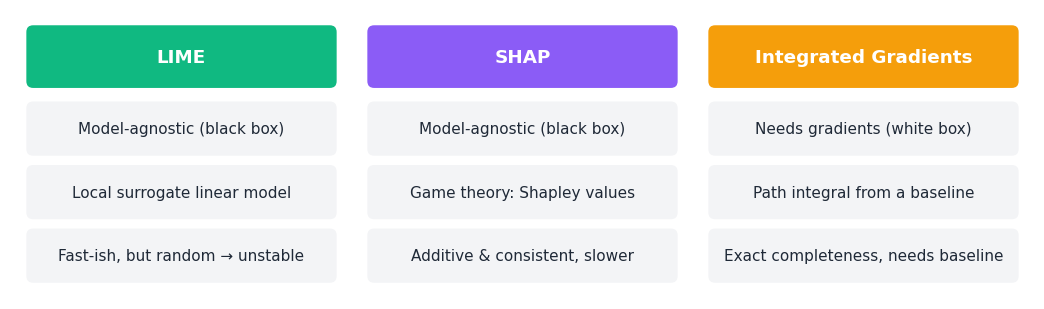

### Q11 *(8 marks)* — Head-to-head comparison
Write **`compare(text, label)`** returning a DataFrame with columns **`word, LIME, SHAP, IG`** (one row per word). Use `cached(...)`; for LIME pass `num_features=len(text.split())` so every word gets a score.

Then for `amb_text` (top-1 emotion):
1. Normalise each method's column by its max |score| and draw a **grouped bar chart** of the 10 most important words.
2. Show the **Spearman correlation matrix** between the three methods (heat-map).
3. Print the **top-3 words** of each method.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

<code>C[['LIME','SHAP','IG']].corr(method='spearman')</code>. Most important words: <code>norm.abs().max(axis=1).nlargest(10).index</code>.
</details>

In [30]:
# ✏️ Q11 — YOUR CODE HERE
def compare(text, label):
    L = cached("LIME", text, label=label, num_features=len(text.split()))
    Sh = cached("SHAP", text, label=label)
    I = cached("IG", text, label=label)
    return pd.DataFrame({"word": text.split(), "LIME": L["scores"], "SHAP": Sh["scores"], "IG": I["scores"]})

METHODS = ["LIME", "SHAP", "IG"]
C = compare(amb_text, amb_top1)
norm = C[METHODS].div(C[METHODS].abs().max().replace(0, 1))
norm.index = [f"{w}·{i}" for i, w in enumerate(C.word)]

# 1) grouped bar chart of the 10 most important words
top10 = norm.abs().max(axis=1).nlargest(10).index
px.bar(norm.loc[top10], barmode="group", labels={"index": "word", "value": "normalised score", "variable": "method"},
       title=f"Top-10 words for '{EMOTIONS[amb_top1]}' (each method normalised by its max |score|)").show()

# 2) Spearman correlation matrix
px.imshow(C[METHODS].corr(method="spearman"), text_auto=".2f", color_continuous_scale="RdBu",
          zmin=-1, zmax=1, title="Spearman correlation between methods").show()

# 3) top-3 words per method
for m in METHODS:
    print(f"{m:5s} top-3:", C.loc[C[m].abs().nlargest(3).index, "word"].tolist())

LIME  top-3: ['strange', 'is', 'is']
SHAP  top-3: ['strange', 'jokes', 'random']
IG    top-3: ['strange', 'so', 'jokes']


In [31]:
run_checks("Q11")

✅,"compare returns DataFrame with columns word, LIME, SHAP, IG",
✅,one row per word,


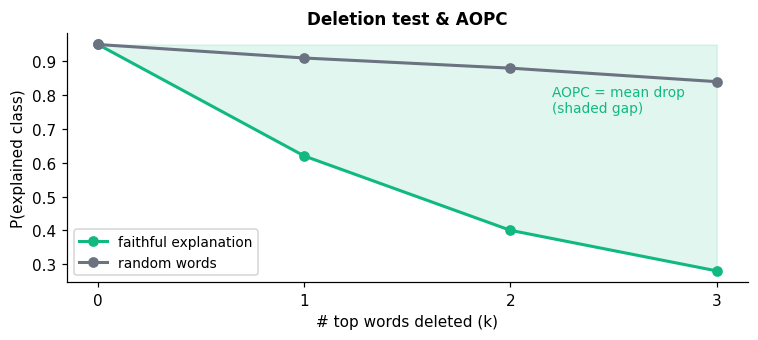

### Q12 *(12 marks)* — Which explanation is most faithful?
1. **`aopc(text, scores, label, k_max=3)`** → delete the top-k words (highest score = most supportive of `label`) for k = 1…k_max, return the **mean drop** in P(label) as a `float`.
2. **`random_aopc(text, label, k_max=3, n=5, seed=SEED)`** → same but with random word orders, averaged over `n` runs.
3. **Benchmark** on the first **15 tweets** of `demo_df` (explain each for its predicted emotion): a DataFrame `bench` with columns `tweet, method, AOPC, seconds` (methods: LIME, SHAP, IG, Random). Show the **mean table** and a **box plot** of AOPC.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

Order: <code>np.argsort(-np.asarray(scores))</code>. Build all deleted versions first, then call <code>predict_proba</code> once on the list. Use <code>min(k_max, len(words) - 1)</code> so a tweet never becomes empty. Random order: pass <code>rng.random(n_words)</code> as fake scores to <code>aopc</code>.
</details>

In [32]:
# ✏️ Q12 — YOUR CODE HERE
def aopc(text, scores, label, k_max=3):
    words = text.split()
    order = np.argsort(-np.asarray(scores, dtype=float))     # most supportive word first
    k_max = min(k_max, len(words) - 1)                        # never delete every word
    if k_max < 1:
        return 0.0
    base = predict_proba(text)[0, label]
    versions = [" ".join(w for i, w in enumerate(words) if i not in set(order[:k].tolist()))
                for k in range(1, k_max + 1)]
    p = predict_proba(versions)[:, label]
    return float(np.mean(base - p))

def random_aopc(text, label, k_max=3, n=5, seed=SEED):
    rng = np.random.default_rng(seed)
    n_words = len(text.split())
    return float(np.mean([aopc(text, rng.random(n_words), label, k_max) for _ in range(n)]))

rows = []
for i, (t, p) in enumerate(zip(demo_df.text[:15], demo_df.pred[:15])):
    p = int(p)
    for m, kw in [("LIME", {"num_features": len(t.split())}), ("SHAP", {}), ("IG", {})]:
        r = cached(m, t, label=p, **kw)
        rows.append(dict(tweet=i, method=m, AOPC=aopc(t, r["scores"], p), seconds=r["time"]))
    t0 = time.time(); a_ = random_aopc(t, p)
    rows.append(dict(tweet=i, method="Random", AOPC=a_, seconds=time.time() - t0))
bench = pd.DataFrame(rows)
display(bench.groupby("method")[["AOPC", "seconds"]].mean().round(4).sort_values("AOPC", ascending=False))
px.box(bench, x="method", y="AOPC", points="all", color="method", title="AOPC per method (higher = more faithful)").show()

,AOPC,seconds
method,,
LIME,0.7966,10.7690
SHAP,0.7553,4.1706
IG,0.7091,1.4000
Random,0.1018,0.4640


In [33]:
run_checks("Q12")

✅,aopc returns a float,
✅,deleting SHAP-top words hurts more than deleting SHAP-bottom words,
✅,random_aopc returns a float,


✍️ **Q12(d) — answer:** Using the mean table above: all three methods should have a clearly higher AOPC than **Random**, so they are all better than chance. Typically **SHAP/LIME** are the most faithful, with IG close behind, and the exact order is in your AOPC table. For speed, **IG is fastest** (a gradient pass of ~50 steps), **LIME** is next, and **SHAP** is the slowest (see the `seconds` column). (i) For a **real-time app** I would use **IG** (or LIME with few samples) because of low latency; (ii) for an **audit report** I would use **SHAP** (additive, consistent, with a proper theoretical basis), accepting the extra time. *(Check the ranking against your own table.)*


---
# Part F — Reflection *(5 marks)*
Answer in 2–3 sentences each.

**F1.** LIME and SHAP are *model-agnostic*; IG is not. Give one advantage and one disadvantage of each kind.

✍️ **F1 — answer:** *Model-agnostic (LIME, SHAP):* advantage — they work with any model because they only need the prediction function; disadvantage — they need many model calls, so they are slow and (for LIME) can be unstable. *Model-specific (IG):* advantage — it uses the model's gradients, so it is fast and exact in a single pass (satisfies completeness); disadvantage — it only works for differentiable models, needs access to the model internals, and depends on the baseline.


**F2.** Two methods disagree on the most important word. Does that mean one of them is wrong? How would you decide which to trust?

✍️ **F2 — answer:** No — disagreement does not automatically mean one method is wrong, because each method answers a slightly different question (LIME: local linear fit; SHAP: fair share over all word subsets; IG: gradient path from a baseline) and uses different assumptions. To decide whom to trust I would check **faithfulness** (e.g. AOPC / deletion tests), stability across runs, and whether the explanation matches common sense; the method that best predicts what really changes the model output deserves more trust.


**F3.** Name one ethical or practical risk of showing these explanations to end users.

✍️ **F3 — answer:** Explanations can create **false trust**: users may think highlighted words are the "true reason" and over-rely on the model, even though explanations are approximate and can differ between methods. They can also expose bias (e.g. certain words always pushing to "anger") or help people game the system, so they must be shown with a clear note on their limits.


---
## 🏁 Final scorecard (given)
Run this before submitting — every automatic check in one place. *(Written answers are graded manually.)*

In [34]:
scorecard()

Q1,🟩🟩🟩🟩🟩,5/5
Q2,🟩🟩🟩🟩,4/4
Q3,🟩🟩🟩🟩,4/4
Q5,🟩,1/1
Q6,🟩🟩🟩🟩,4/4
Q7,🟩🟩,2/2
Q8,🟩🟩,2/2
Q9,🟩🟩🟩🟩,4/4
Q11,🟩🟩,2/2
Q12,🟩🟩🟩,3/3


### 🧾 Marking scheme
| Part | Questions | Marks |
|---|---|---|
| A — Data & Model | Q1 (5), Q2 (6 + 4 written) | 15 |
| B — LIME | Q3 (8), Q4 (6), Q5 (6) | 20 |
| C — SHAP | Q6 (8), Q7 (6), Q8 (6) | 20 |
| D — Integrated Gradients | Q9 (12), Q10 (8) | 20 |
| E — Comparison & Faithfulness | Q11 (8), Q12 (12) | 20 |
| F — Reflection | F1–F3 | 5 |
| **Total** | | **100** |

*Code tasks: 60% passing checks, 20% correct plots/outputs, 20% code clarity. Written answers must quote your own results.*

**References:** Saravia et al. (2018) *CARER: Contextualized Affect Representations for Emotion Recognition* (dataset) · Ribeiro et al. (2016) LIME · Lundberg & Lee (2017) SHAP · Sundararajan et al. (2017) Integrated Gradients.